# 다항 회귀 PolynomialFeatures
- 데이터들간의 형태가 비선형 일때,데이터에 각 특성(입력값)의 제곱,세제곱을 추가해 특성이 추가된 비선형 데이터를 선형 회귀 모델로 훈련시키는 방법 - 곡선형태

- 항이 많을 수록 정확도 올라감.

In [9]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression 
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler  # 정규화클래스
from sklearn.model_selection import train_test_split

In [16]:
# 데이터전처리
perch_length = np.array(
    [8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0, 
    21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5, 
    22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5, 
    27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0, 
    36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0, 
    40.0, 42.0, 43.0, 43.0, 43.5, 44.0]
    )
perch_weight = np.array(
    [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0, 
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0, 
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0, 
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0, 
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0, 
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0, 
    1000.0, 1000.0]
    )

In [17]:
# 학습데이터, 테스트데이터 분리
train_data,test_data,train_label,test_label = train_test_split(perch_length,perch_weight)

In [28]:
train_data=train_data.reshape(-1,1)
train_data[:2]
test_data=test_data.reshape(-1,1)
test_data[:2]

array([[34.5],
       [36. ]])

In [ ]:
# 데이터 전처리- 다항회귀
# train_data [[43.5**2, 43.5]]
train_poly = np.column_stack((train_data**2,train_data))
test_poly = np.column_stack((test_data**2,test_data))
train_poly[:2]
test_poly[:2]

array([[1190.25,   34.5 ],
       [1296.  ,   36.  ]])

In [22]:
#데이터 학습
lr= LinearRegression()
lr.fit(train_poly,train_label)

#데이터 예측
predict = lr.predict(test_poly)
print('무게예측: ',predict)

#정확도
score= lr.score(train_poly,train_label)
score2= lr.score(test_poly,test_label)
print("train정확도",score)
print("test정확도",score2)


무게예측:  [570.72111404 643.29348181  77.77229192 136.61167806 201.80474929
 801.60344015 977.46702887  10.45820295 257.78381424 115.04814597
 115.04814597 136.61167806 148.12484537 290.0745649 ]
train정확도 0.9684379044157174
test정확도 0.9846093580495768


In [38]:
in_data = 25
result = lr.predict([[in_data**2,in_data]])
print("예측무게: ",result)

예측무게:  [213.00469458]


In [23]:
# 기울기
print(lr.coef_,lr.intercept_)

[  0.97520169 -20.3701405 ] 112.75715206785588


In [ ]:
# point : 곡선을 그릴 때 사용할 길이
point= np.arange(15,50)
print(lr.coef_,lr.intercept_)

[  0.97520169 -20.3701405 ] 112.75715206785588


In [40]:
point

array([15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31,
       32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48,
       49])

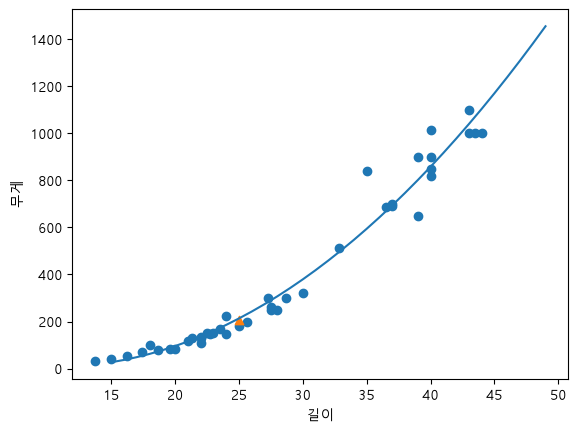

In [39]:
#산점도 그래프
plt.scatter(train_data,train_label)
plt.scatter(25,208,marker="^")

plt.plot(point,lr.coef_[0]*point**2+lr.coef_[1]*point+lr.intercept_)
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()

In [13]:
data = np.column_stack((perch_length,perch_weight))
data[:2]

array([[ 8.4,  5.9],
       [13.7, 32. ]])

In [26]:
data

array([[   8.4,    5.9],
       [  13.7,   32. ],
       [  15. ,   40. ],
       [  16.2,   51.5],
       [  17.4,   70. ],
       [  18. ,  100. ],
       [  18.7,   78. ],
       [  19. ,   80. ],
       [  19.6,   85. ],
       [  20. ,   85. ],
       [  21. ,  110. ],
       [  21. ,  115. ],
       [  21. ,  125. ],
       [  21.3,  130. ],
       [  22. ,  120. ],
       [  22. ,  120. ],
       [  22. ,  130. ],
       [  22. ,  135. ],
       [  22. ,  110. ],
       [  22.5,  130. ],
       [  22.5,  150. ],
       [  22.7,  145. ],
       [  23. ,  150. ],
       [  23.5,  170. ],
       [  24. ,  225. ],
       [  24. ,  145. ],
       [  24.6,  188. ],
       [  25. ,  180. ],
       [  25.6,  197. ],
       [  26.5,  218. ],
       [  27.3,  300. ],
       [  27.5,  260. ],
       [  27.5,  265. ],
       [  27.5,  250. ],
       [  28. ,  250. ],
       [  28.7,  300. ],
       [  30. ,  320. ],
       [  32.8,  514. ],
       [  34.5,  556. ],
       [  35. ,  840. ],
